# HPP: Mixtral-8x7B-Instruct

32 layers all-MoE - 8 routed experts, top-2 - D=14336, d=4096 - tightest arch: REAP hits its floor at 75%

**Hierarchy:** `total budget -> layer budgets (ALPHA) -> dynamic expert drop (gamma floors) -> survivor widths (BETA) -> channels`

| symbol | role |
|---|---|
| `gamma` | per-expert energy-retention threshold -> sets each expert's channel FLOOR |
| `alpha` | LAYER allocation exponent (depth-aware budget split) |
| `beta`  | EXPERT allocation exponent (saliency-weighted survivor widths) |

Special cases recovered: high gamma -> REAP (drop whole experts); low gamma + beta=0 -> SlimMoE (uniform slim).

All logic lives in the `hpp` package, this notebook only chooses knobs and calls runners. Every step is cached and resumable.

### 1: Setup

`CUDA_VISIBLE_DEVICES` must be set before torch is imported, which is why it cannot live inside the config.

In [ ]:
import os
import sys
from pathlib import Path

GPU_ID = "0"
os.environ["CUDA_VISIBLE_DEVICES"] = GPU_ID

root = Path.cwd()
if not (root / "hpp").exists() and (root.parent / "hpp").exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))


from hpp.models import build
from hpp import runners, gamma as gamma_mod, reconstruction
from hpp.floors import gamma_to_floors
from hpp.plots.saliency import plot_floors
from hpp.plots.pca import pca_functional_subspace
from hpp.results import before_after_table

cfg, adapter = build("mixtral8x7b", quantize=True)
print(cfg.model_tag, cfg.prec_tag, "| sparsities", cfg.sparsities,
      "| recon", cfg.recon.sparsities)
print("results ->", cfg.res_dir)

mixtral8x7b nf4 | sparsities (0.25, 0.5, 0.75) | recon (0.75,)
results -> results_mixtral_nf4


In [2]:
from huggingface_hub import constants as hfc
print("HF_HUB_CACHE:", hfc.HF_HUB_CACHE)

HF_HUB_CACHE: /tmp/an261-hf-cache/hub


### 2: profile, to scores, to diagnostics

One forward pass over the packed calibration set fills every statistic the three saliency levels need. Cached per (model, precision, calibration shape); the GPU is freed before returning.

Emits: layer-importance bars (ALPHA driver), expert-saliency heatmap (BETA driver), REAP-saliency heatmap (the baseline's own scoring), and the three convergence panels.

cache hit (scores + profile) [nf4]
  [guard] 0 experts below the activation floor, 0 leak (must be 0)


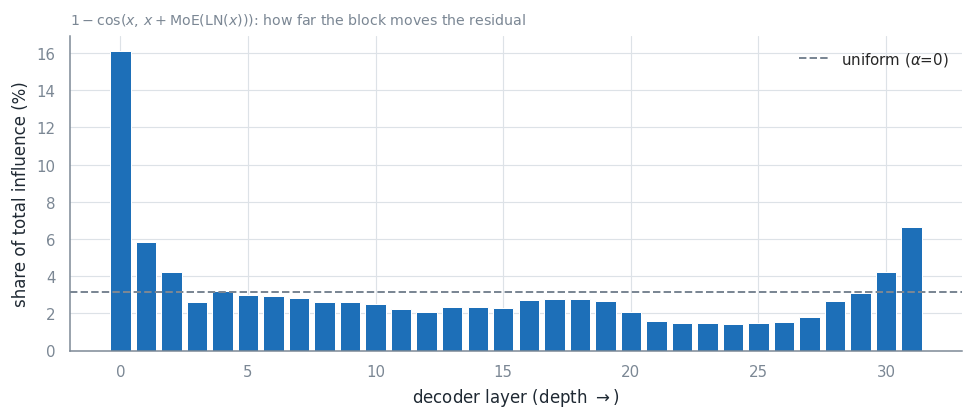

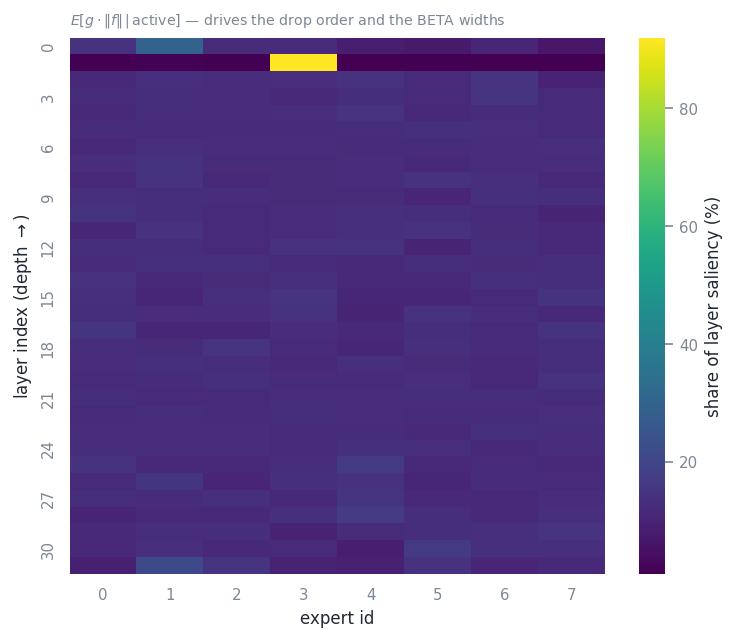

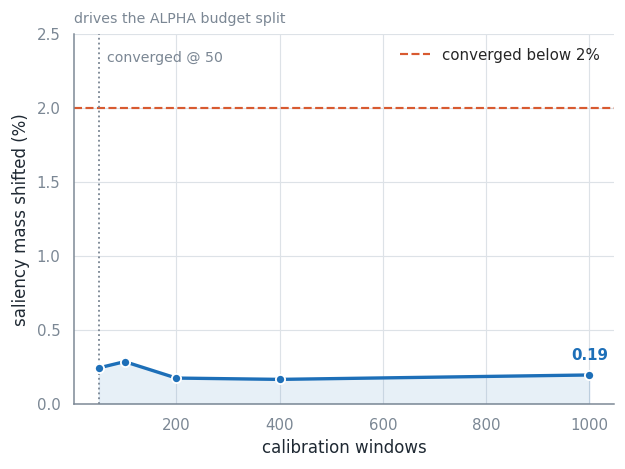

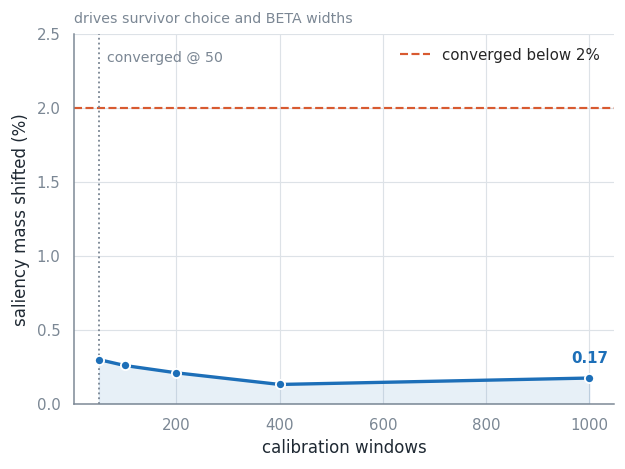

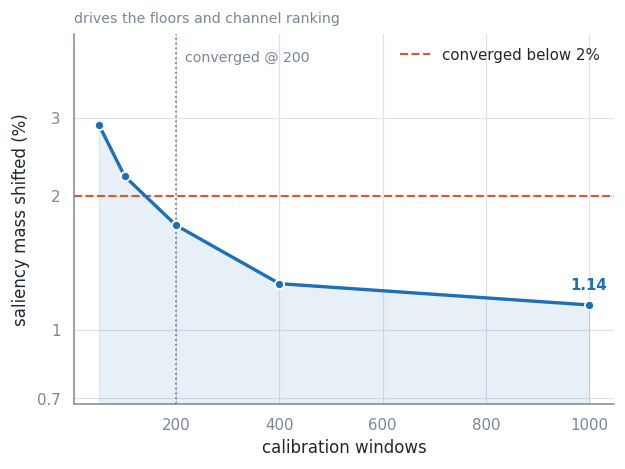

In [3]:
scores, prof = runners.setup(cfg, adapter)

### 3: calibrate gamma

gamma is **read off the model**, not chosen: probe the whole-expert cliff on GPU to find how many experts this model actually tolerates (m*), then pick the gamma whose floors reproduce m* offline. Skip by setting `cfg.gamma = <value>` directly.

  answer key @ s=50%: best perplexity=6.0466 (lower is better), threshold=6.7184 -> 5 survivors (drop 3)
  -> calibrated gamma = 0.906 (mean floor 77.3% of D)


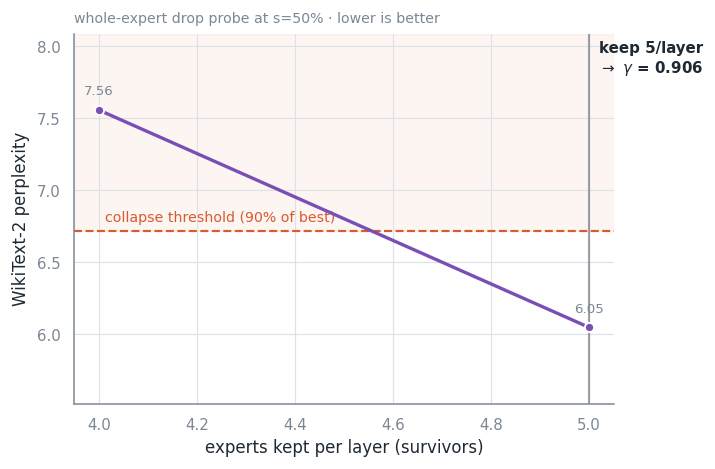

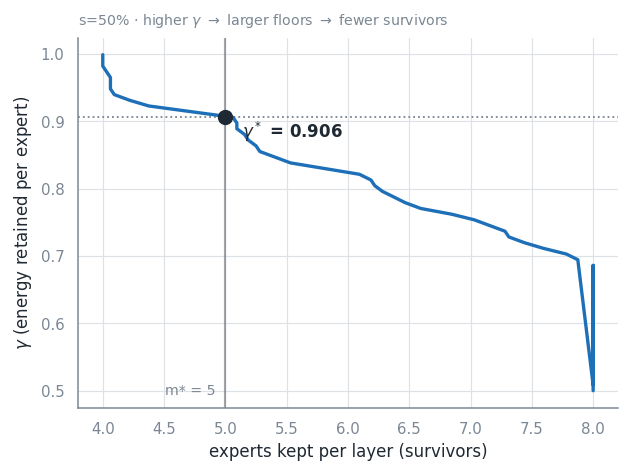

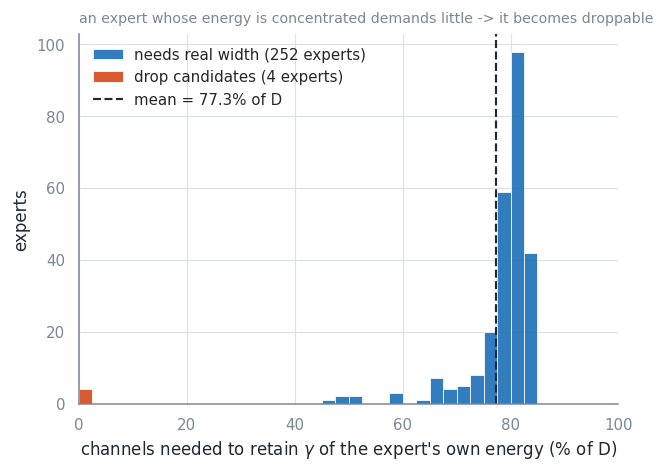

gamma = 0.9059661016949152


In [4]:
if cfg.gamma is None:
    if not cfg.dropkey_csv.exists():
        gamma_mod.ensure_drop_keys(cfg, adapter, scores)   # GPU: reloads the model per probe
    cfg.gamma, curve = gamma_mod.calibrate_gamma(cfg, scores)

plot_floors(cfg, gamma_to_floors(cfg, scores, cfg.gamma), cfg.gamma)
print("gamma =", cfg.gamma)

### 4: functional subspace (REAP Fig. 1 analogue)

Does the surviving set still span the original experts' output space? One PCA per layer, three panels sharing coordinates: Original / REAP / HPP.

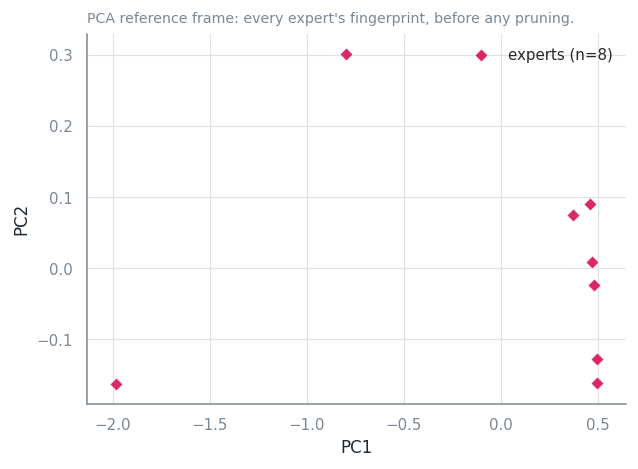

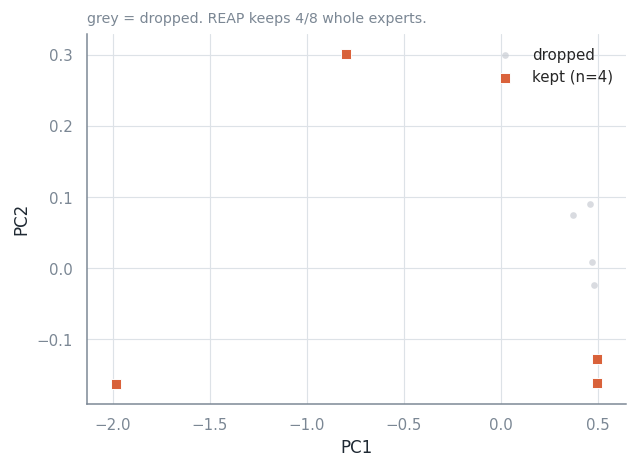

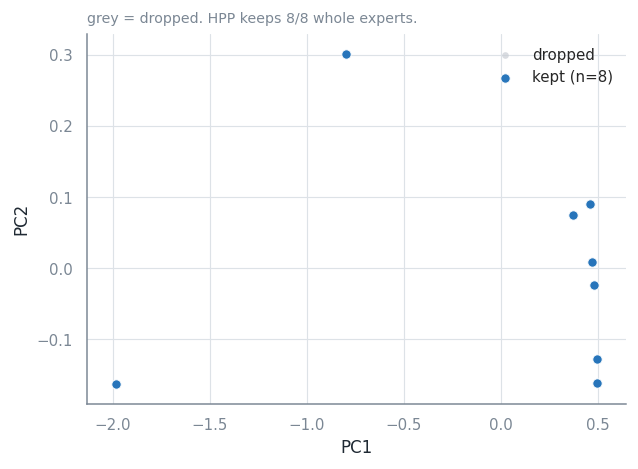

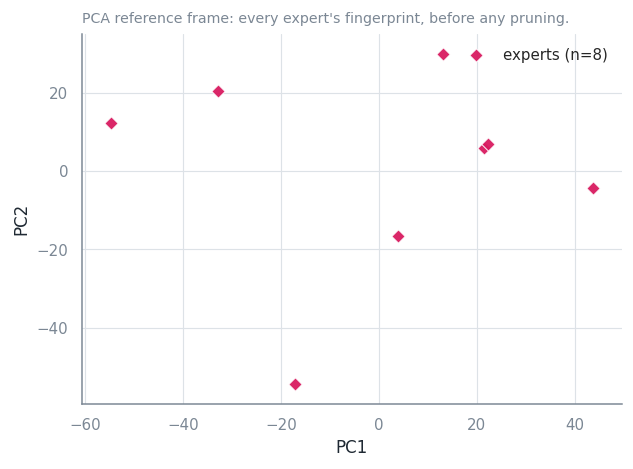

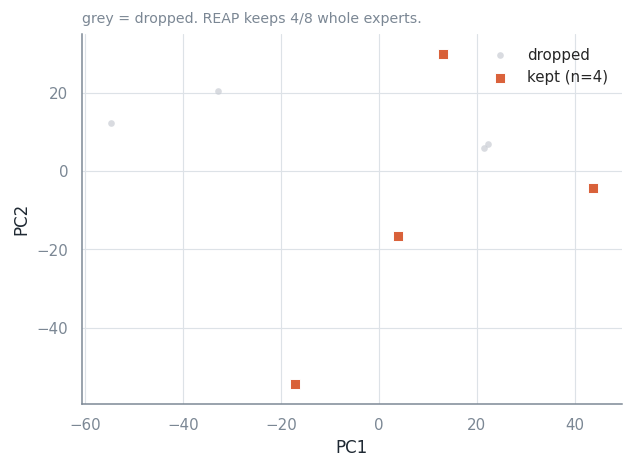

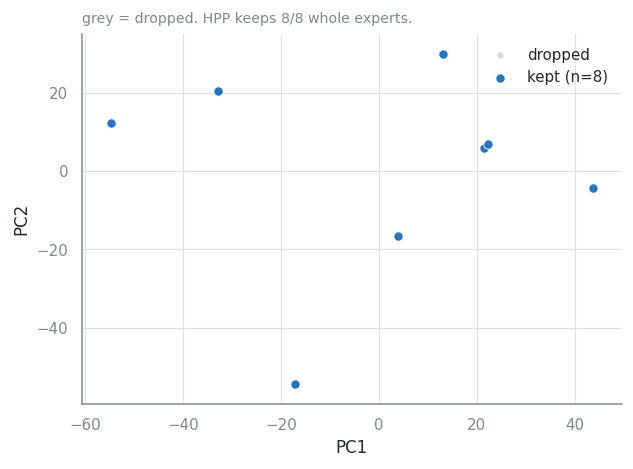


  PC1+PC2 cumulative variance explained (cf. REAP Table A4):
 layer_id  evr_original  evr_reap  evr_hpp  reap_survivors  hpp_survivors
        0        0.9723    0.9944   0.9723               4              8
       31        0.5676    0.7564   0.5676               4              8


,layer_id,evr_original,evr_reap,evr_hpp,reap_survivors,hpp_survivors
0,0,0.9723,0.9944,0.9723,4,8
1,31,0.5676,0.7564,0.5676,4,8


In [5]:
pca_functional_subspace(cfg, scores, sparsity=0.50)

### 5: baseline + sweep

Every sparsity point goes through `run_hpp`/`run_reap`, so each one leaves its allocation CSV, pruned-index NPZ and kept-capacity heatmap behind, not just a CSV row.

In [6]:
PROFILE = "fast_sweep"    

runners.run_baseline(cfg, adapter, PROFILE)

  [skip] baseline



SWEEP [nf4] mixtral8x7b: alpha=1.0 beta=1.0 gamma=0.906 profile=fast_sweep
  [skip] HPP s=25% a=1.0 b=1.0
  [skip] REAP s=25%
  [skip] HPP s=50% a=1.0 b=1.0
  [skip] REAP s=50%
  [skip] HPP s=75% a=1.0 b=1.0
  [skip] REAP s=75%


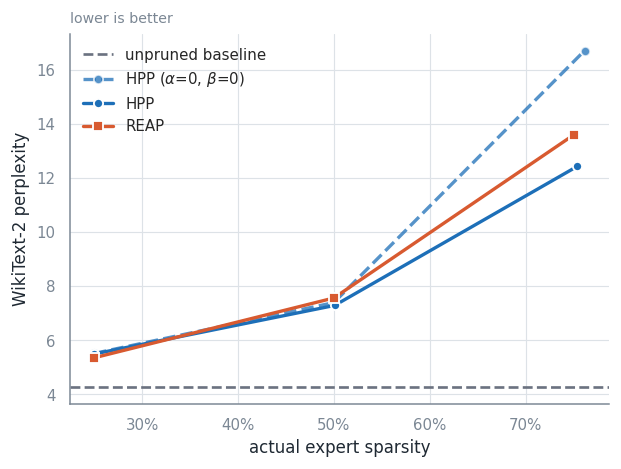

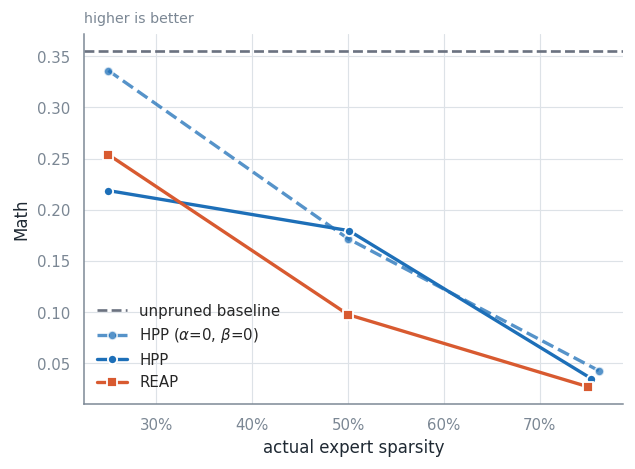

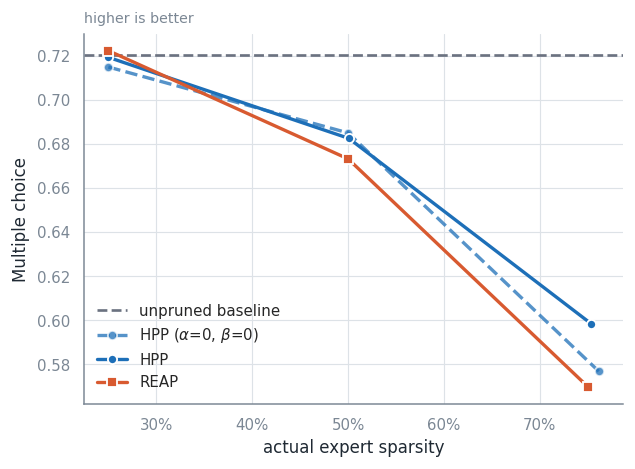

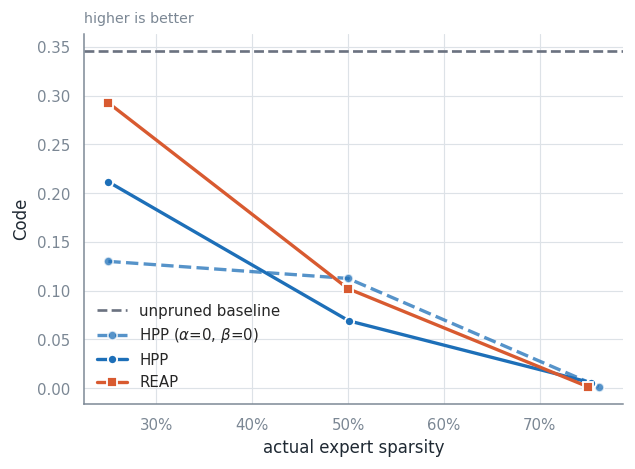

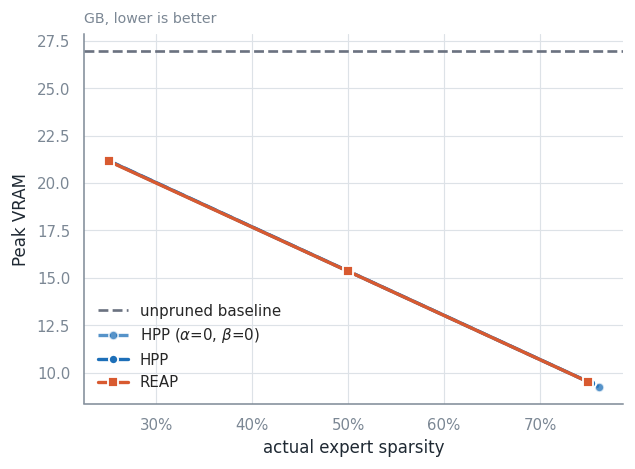

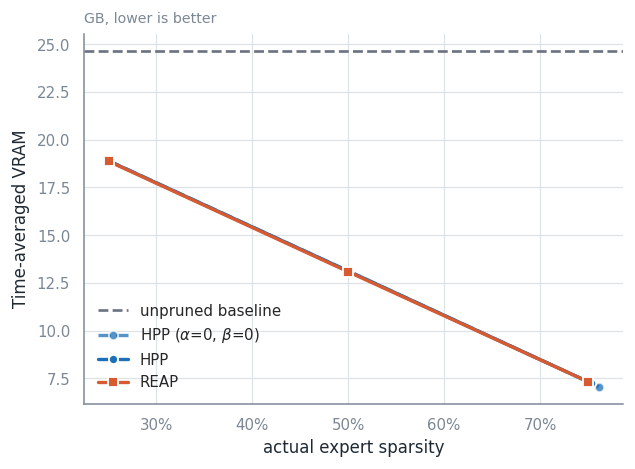

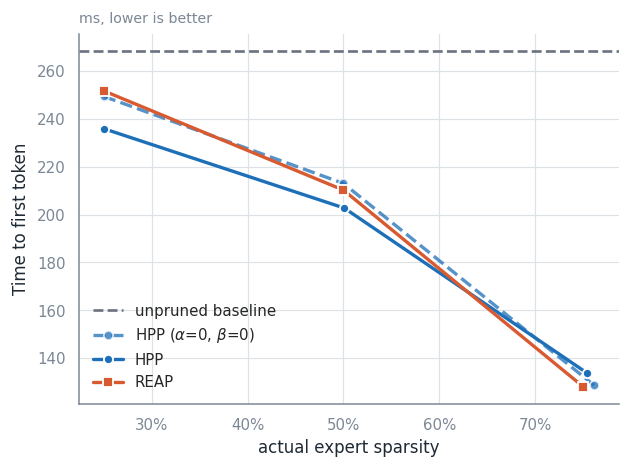

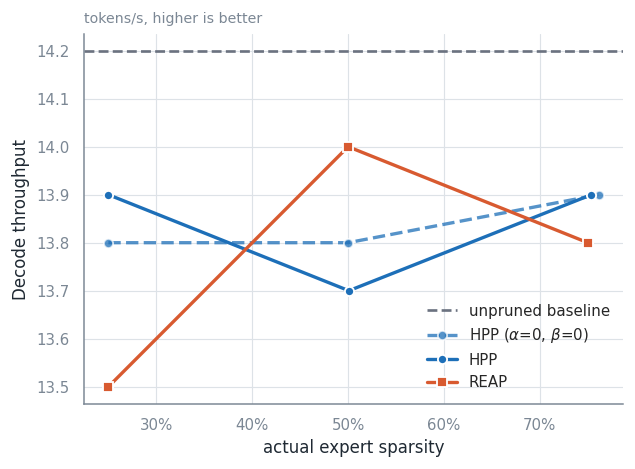

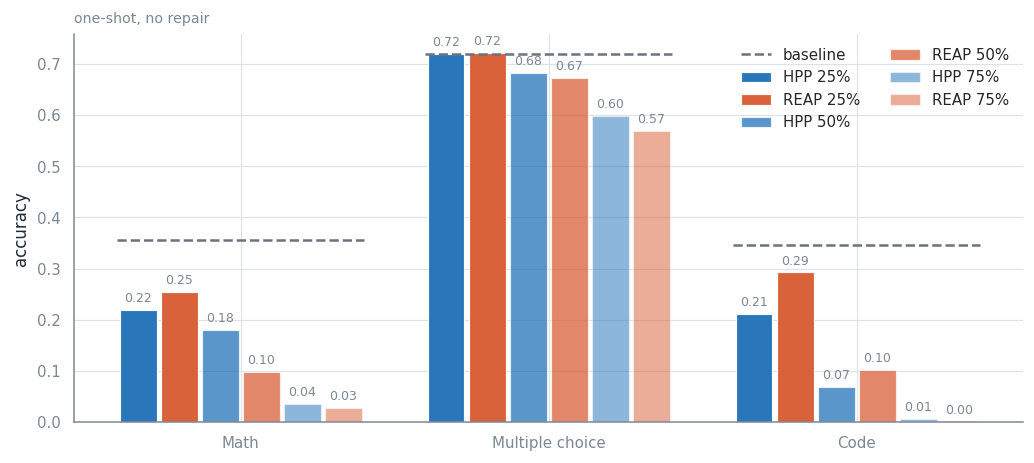

In [7]:
runners.run_sweep(cfg, adapter, scores, profile=PROFILE)

### Ablation: uniform allocation (alpha = beta = 0)

Isolates what the depth-aware and saliency-weighted allocation actually buy over spending the same budget uniformly.


SWEEP [nf4] mixtral8x7b: alpha=0.0 beta=0.0 gamma=0.906 profile=fast_sweep
  [skip] HPP s=25% a=0.0 b=0.0
  [skip] REAP s=25%
  [skip] HPP s=50% a=0.0 b=0.0
  [skip] REAP s=50%
  [skip] HPP s=75% a=0.0 b=0.0
  [skip] REAP s=75%


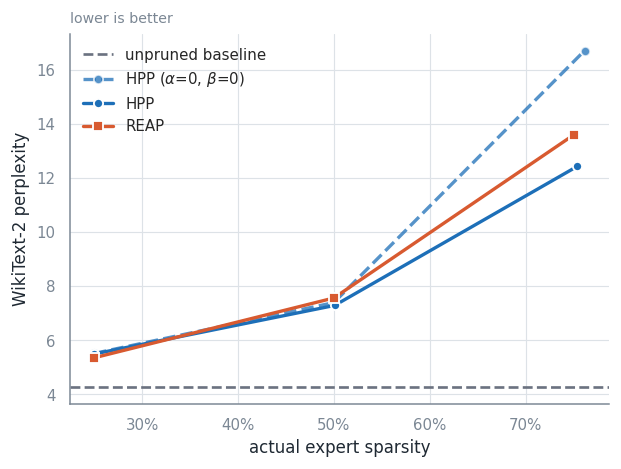

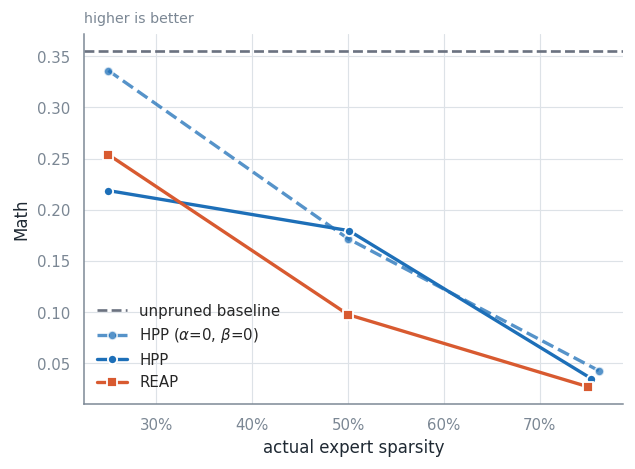

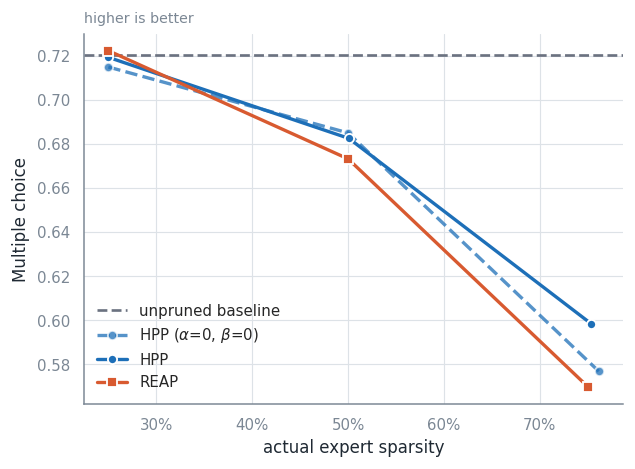

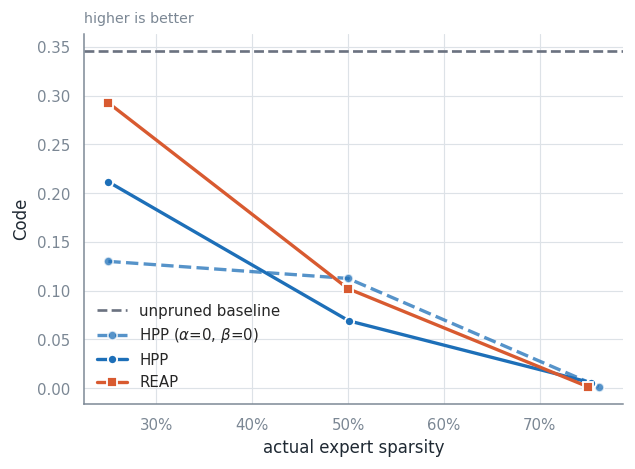

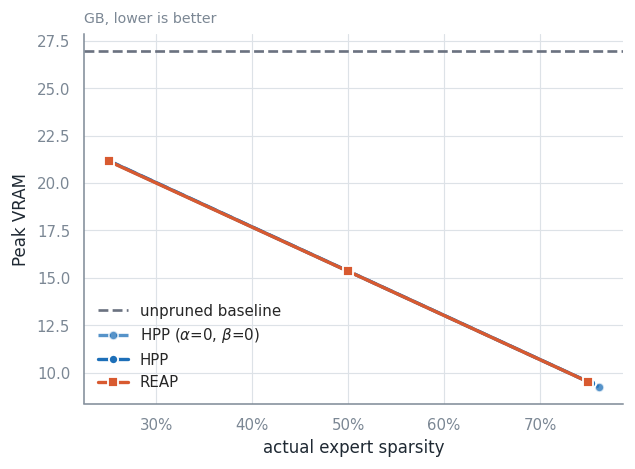

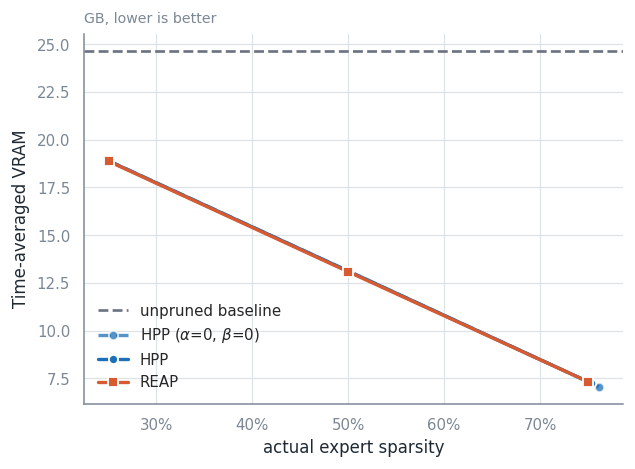

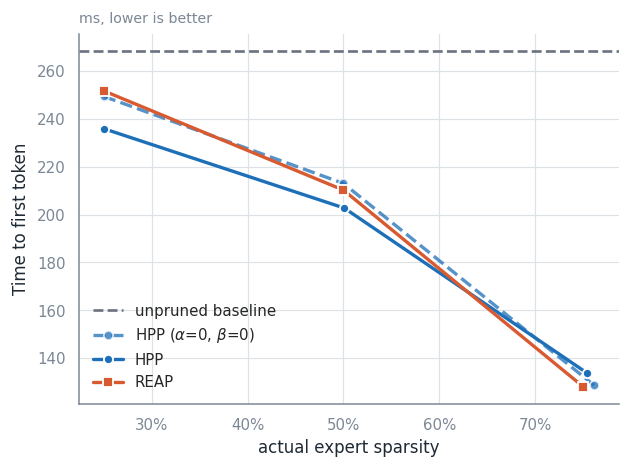

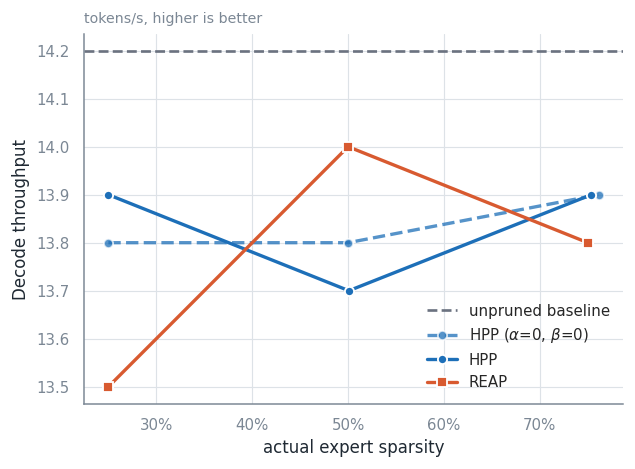

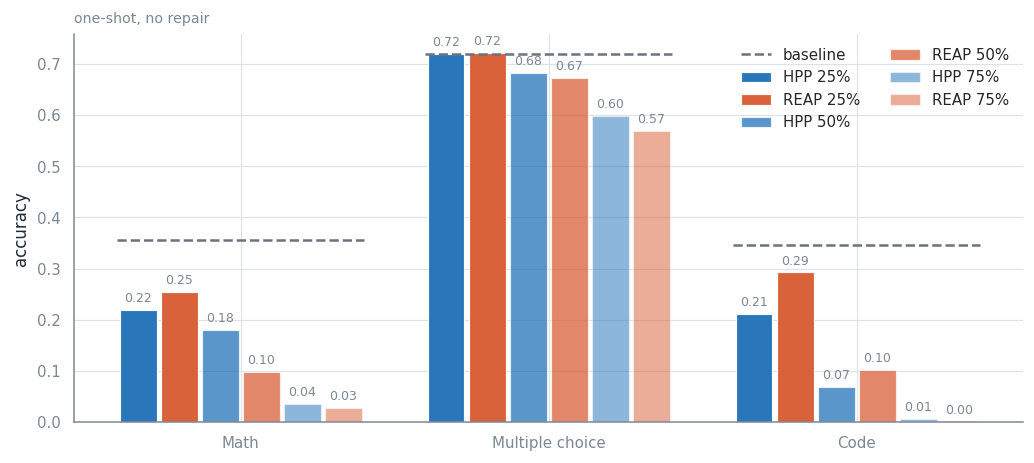

In [8]:
runners.run_sweep(cfg, adapter, scores, alpha=0.0, beta=0.0, profile=PROFILE)

### 6: LoRA reconstruction (C4)

Does HPP's channel selection leave more *repairable* structure than REAP's whole-expert selection? LoRA on surviving experts' gate/up/down only; router and attention frozen. Identical seed, data order and schedule for both methods.

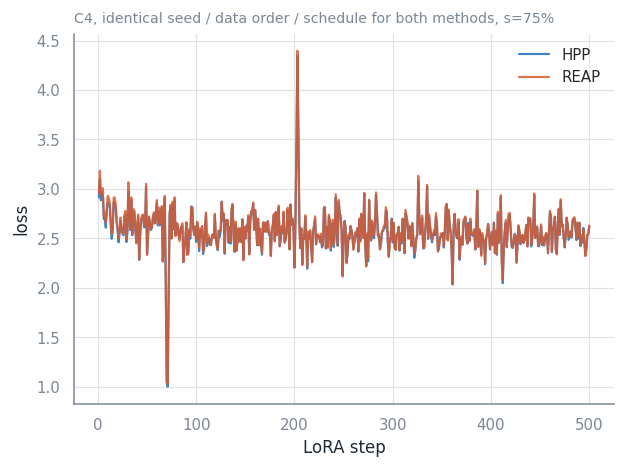

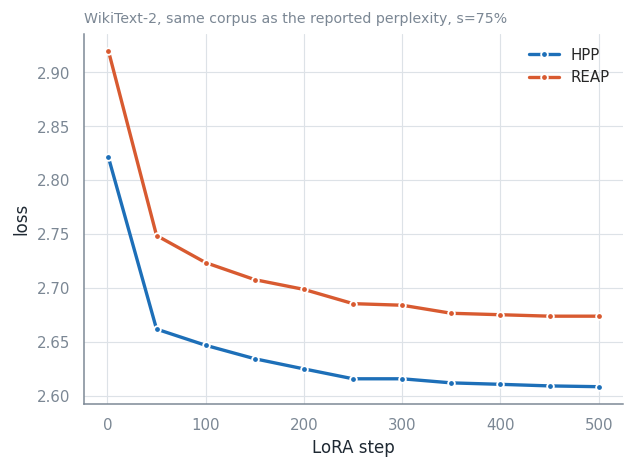

  [WARNING] 2 rows match hpp s=75% (alpha/beta: [(1.0, 1.0), (0.0, 0.0)]) -- using the first
  [skip] repaired hpp s=75% already logged
  [skip] repaired reap s=75% already logged
Method Sparsity  perplexity (before)  perplexity (after)  recovered %
   HPP    75.4%              12.4235              9.5581         23.1
  REAP    75.0%              13.5872              9.7276         28.4


,Method,Sparsity,perplexity (before),perplexity (after),recovered %
0,HPP,75.4%,12.4235,9.5581,23.1
1,REAP,75.0%,13.5872,9.7276,28.4


In [9]:
reconstruction.run_all_reconstructions(cfg, adapter, scores)

for s in cfg.recon.sparsities:
    for m in ("hpp", "reap"):
        reconstruction.evaluate_repaired(cfg, adapter, scores, m, s)

before_after_table(cfg, PROFILE, "perplexity")

### 7: math-trained reconstruction ablation: HPP vs REAP, s=75%

Same math-only LoRA repair as the DeepSeek/gpt-oss notebooks (`microsoft/orca-math-word-problems-200k`, chat-formatted, prompt masked, disjoint from GSM8K/MATH-500's own train/test split). Own CSV (`ablation_math_reconstruction.csv`), own per-sparsity figure, doesn't touch `sweep.csv`/`sweep_reconstructed.csv`/the existing C4-trained LoRAs above. Code eval off by default (barely moved on DeepSeek's runs); pass `include_code=True` if wanted.

  [skip] math-recon training hpp s=75% already done (lora_mathrecon_hpp_s75_mixtral8x7b.pt exists)
  [WARNING] 2 rows match hpp s=75% (alpha/beta: [(1.0, 1.0), (0.0, 0.0)]) -- using the first
  [skip] math-recon eval hpp s=75% already logged
  [skip] math-recon training reap s=75% already done (lora_mathrecon_reap_s75_mixtral8x7b.pt exists)
  [skip] math-recon eval reap s=75% already logged
  [WARNING] 2 rows match hpp s=75% (alpha/beta: [(1.0, 1.0), (0.0, 0.0)]) -- using the first
  [WARNING] 2 rows match hpp s=75% (alpha/beta: [(1.0, 1.0), (0.0, 0.0)]) -- using the first


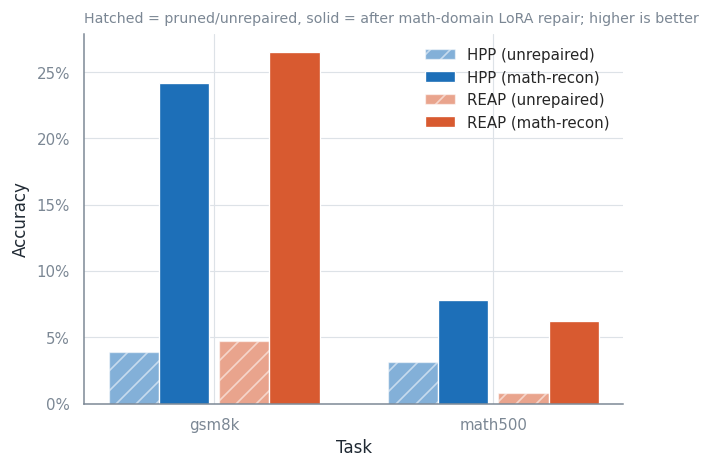

In [10]:
from hpp import ablation

math_recon_df = ablation.run_math_reconstruction_ablation(cfg, adapter, scores, sparsity=(0.75))